# 02 · Lexical search com BM25

**Objetivo:** construir e avaliar o retrieval de referência: um índice BM25 sobre o texto dos produtos, seguindo o protocolo de [docs/EVALUATION.md](../docs/EVALUATION.md).

**Regras deste notebook**
- **O test set não é usado:** nem os `label`, nem o texto das queries do test set. As análises de queries usam só o train set e o validation set.
- O catalog (`product.csv`) é o mesmo para os três sets e não tem `label`, então é analisado inteiro.

**Como ler este notebook**
- Cada seção começa explicando a pergunta que ela responde, e pode ser lida sozinha.
- Toda tabela e todo gráfico têm um título que diz o que é medido e em quais dados.
- As conclusões ficam logo abaixo da célula que as sustenta, sempre no mesmo formato:
  - **Resultados:** o que as saídas mostram, um fato por item.
  - **Suposições:** o que tomamos como verdadeiro sem verificar, e o que muda se não for.
  - **Limitações:** o que a medição não captura.
  - **Escolhas e alternativas:** cada escolha, se está decidida ou só proposta, e as outras opções.
- Os termos técnicos ficam em inglês e estão definidos na seção "Termos usados no notebook". Os termos são os mesmos de `01_eda_revised.ipynb`.

**Etapas**
1. O indexed text: o que entra no índice
2. Índice, busca, entradas inválidas e latência
3. Avaliação do BM25 baseline no train set e no validation set
4. BM25 v2: plurais e `product_features` sem `yes`/`no` e sem números
5. BM25 v3: a key dos values `yes`

## TL;DR

- **BM25 de referência: a v2.** Remove plurais (`chairs` → `chair`) e tira de `product_features` os values `yes`, `no` e só numéricos; `k1 = 1.2`, `b = 0.5`. NDCG@10 de 0,653 no validation set, contra 0,620 do baseline (+0,033 [0,014; 0,056]) (Etapa 4).
- **O ganho da v2 está na ordem do topo, não na cobertura:** Capped Recall@100 fica em 0,705, contra 0,702 do baseline. Com BM25 sozinho, o ranking recebe cerca de 70% dos Exact que poderia receber (Etapas 3.1 e 4.3).
- **A v3 (key dos values `yes` no indexed text) não se distingue da v2** em nenhuma métrica, e a v2 fica por ser mais simples (Etapa 5).
- **Um quarto dos 10 primeiros resultados não tem `label`.** Sem esses produtos, o NDCG@10 do baseline subiria 0,12 a 0,16; parte do ganho da v2 vem de trazer mais produtos julgados para o topo (Etapas 3.2 e 4.3).
- **26 das 384 queries do train e do validation set têm tokens que o catalog não tem** (typos, marcas, palavras grudadas); uma (`minnestrista`) não tem nenhum e tem nota 0 em qualquer lexical search (Etapa 1.4).
- **Próximo passo:** semantic search e hybrid search, para aumentar a cobertura dos 100 candidatos.

## Termos usados no notebook

| Termo | Significado | Exemplo |
|---|---|---|
| query | Texto que uma pessoa digitou na busca da loja (coluna `query` de `query.csv`). | "leather chair" |
| catalog | Os 42.994 produtos de `product.csv`. | |
| label | Julgamento humano de um par (query, produto): Exact, Partial ou Irrelevant. | |
| judged pair | Par (query, produto) que tem `label`. Um produto retornado para uma query com que não forma judged pair é um produto **sem `label`**. | |
| split | Divisão das queries em **train set** (escolher parâmetros), **validation set** (comparar sistemas) e **test set** (medir uma única vez, no fim). A coluna `split` de `splits/query_split.csv` diz em qual set cada query está. | |
| token | Palavra do texto, depois de remover acentos, passar para minúsculas e separar em tudo que não é letra ou dígito (`text.tokenize`). Aqui, diferente da EDA, **as repetições contam**, porque o BM25 conta quantas vezes cada token aparece. | `'Fawkes 36" Blue-Vanity'` → `fawkes`, `36`, `blue`, `vanity` |
| vocabulary | Conjunto de tokens distintos de um texto ou do catalog. | |
| field | Uma das colunas de texto do produto usadas na busca: `product_name`, `product_class`, `category_hierarchy`, `product_description` e `product_features`. | |
| single field | O texto dos cinco fields, emendados nessa ordem, um por produto. É o indexed text do baseline. | |
| indexed text | O texto em que o retrieval procura a query. | |
| key:value pair | Cada item de `product_features`. Em `color : caramel`, a key é `color` e o value é `caramel`. | |
| lexical search | Retrieval que procura os tokens da query no indexed text. BM25 é o método clássico. | |
| semantic search / hybrid search | Retrieval pelo significado, com embeddings; hybrid search combina lexical e semantic search. | |
| BM25 | Score de um produto para uma query: soma, sobre os tokens da query, de quantas vezes o token aparece no produto, pesando mais tokens raros no catalog e menos textos longos. `k1` controla quanto as repetições de um token contam; `b`, quanto o tamanho do texto penaliza. | |
| ranking / reranker | Segunda fase: um modelo reordena os 100 primeiros candidatos do retrieval. | |
| tuning | Escolher `k1` e `b` testando uma grade de valores no train set. | |
| ablation | Medir o efeito de cada mudança separadamente, tirando uma de cada vez. | |
| error analysis | Olhar as queries com nota baixa para entender por que o sistema errou. | |
| typo | Erro de digitação. | `ligth` |
| stemming | Reduzir palavras a um radical comum. Aqui usamos só a remoção de plural (S-stemmer). | `chairs` → `chair` |

### Métricas

As métricas seguem `docs/EVALUATION.md`. Todas são calculadas por query e depois tiradas na média entre as queries.

| Métrica | O que mede | Queries |
|---|---|---|
| **NDCG@10** (principal) | Qualidade da ordem dos 10 primeiros. **Gain** é quanto cada produto vale: Exact = 2, Partial = 1, Irrelevant = 0, e produto sem `label` = 0. Os primeiros pesam mais. Vai de 0 a 1; 1 é a melhor ordem possível para a query. | todas |
| **MRR@10** | 1 / posição do primeiro Exact nos 10 primeiros; 0 se não houver. 0,5 = primeiro Exact na posição 2. | só as com Exact |
| **Capped Recall@K** | Exact encontrados nos K primeiros ÷ min(K, número de Exact da query). Mede a cobertura dos candidatos que o ranking vai receber. `capped_recall@100_exact_partial` conta Exact e Partial. | só as com Exact |
| **judged@10** | Fração dos 10 primeiros que têm `label`. | todas com resultado |
| **condensed NDCG@10** | NDCG@10 depois de tirar da lista os produtos sem `label`. | todas |
| **latency_ms_p50 / p95** | Tempo de uma busca, em milissegundos: mediana e percentil 95. | todas |

**Bootstrap confidence interval:** sorteamos as queries com reposição e recalculamos a média, 2.000 vezes (seed 0); o intervalo de 95% vai do percentil 2,5 ao 97,5. **Paired bootstrap:** o mesmo, mas sobre a diferença entre dois sistemas na mesma query. Se o intervalo da diferença contém 0, não distinguimos os dois sistemas.

## Setup

In [1]:
import platform
import time

import bm25s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from wands_search import data, evaluate, metrics, plots, profiling, retrieval, split, text

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

products = data.load_products()
queries = data.load_queries()
labels = data.deduplicate_labels(data.load_labels())
labels_by_query = metrics.labels_by_query(labels)
query_split = evaluate.load_split()

print("pandas", pd.__version__, "| numpy", np.__version__, "| bm25s", bm25s.__version__)
print("products:", len(products), "| queries:", len(queries), "| judged pairs after deduplication:", len(labels))

pandas 3.1.1 | numpy 2.5.4 | bm25s 0.3.16
products: 42994 | queries: 480 | judged pairs after deduplication: 231859


## Etapa 1 · O indexed text

Antes de construir o índice, olhamos o que entra nele: o texto de cada field, depois de `text.product_field_texts`, e os tokens que saem de `text.tokenize`. Queries e produtos passam pelo mesmo processamento.

### 1.1 · Um produto, field a field

`product_features` entra só com os values, sem as keys (`color : caramel` vira `caramel`), como proposto na Etapa 2.5 da EDA. O exemplo é o produto 0, uma cama.

In [2]:
field_texts = text.product_field_texts(products)
single_field_texts = text.single_field_text(field_texts)

EXAMPLE_PRODUCT_ID = 0
example_fields = pd.DataFrame({
    "text": field_texts.loc[EXAMPLE_PRODUCT_ID],
    "tokens": field_texts.loc[EXAMPLE_PRODUCT_ID].map(lambda value: len(text.tokenize(value))),
}).rename_axis("field")
display(plots.table(example_fields, f"Text of each field of product {EXAMPLE_PRODUCT_ID} and its number of tokens",
                    note="Texts longer than 120 characters are cut."))
print("single field, first 40 tokens:", text.tokenize(single_field_texts.loc[EXAMPLE_PRODUCT_ID])[:40])

,text,tokens
field,,
product_name,solid wood platform bed,4
product_class,Beds,1
category_hierarchy,Furniture / Bedroom Furniture / Beds & Headboards / Beds / Twin Beds,8
product_description,"good , deep sleep can be quite difficult to have in this busy age . fortunately , there ’ s an antidote to such a pro...",175
product_features,64.7 modern made in viet nam slat 25.35 500 120 77.9 full assembly needed 78.7 rubberwood 12 39.6 rectangular acacia ...,116


single field, first 40 tokens: ['solid', 'wood', 'platform', 'bed', 'beds', 'furniture', 'bedroom', 'furniture', 'beds', 'headboards', 'beds', 'twin', 'beds', 'good', 'deep', 'sleep', 'can', 'be', 'quite', 'difficult', 'to', 'have', 'in', 'this', 'busy', 'age', 'fortunately', 'there', 's', 'an', 'antidote', 'to', 'such', 'a', 'problem', 'a', 'nice', 'quality', 'bed', 'frame']


**Resultados**
- **No single field, `product_name` é uma parte pequena:** no produto 0, tem 4 dos 304 tokens. `product_description` tem 175, e `product_features`, 116.
- **Sem as keys, os values de `product_features` perdem o contexto:** `64.7`, `25.35` e `500` são medidas, mas viram só números; `full assembly needed` aparece sem dizer a que se refere.
- **O apóstrofo quebra palavras:** `there ’ s` vira `there` e `s`. O mesmo vale para o apóstrofo comum e para as queries. Não medimos quantas vezes isso ocorre.

**Limitações**
- É um único produto, escolhido como exemplo. Os números do catalog inteiro estão na Etapa 1.2.

### 1.2 · Tamanho de cada field, em tokens

Para cada field: a fração de produtos com o field vazio, a mediana, o percentil 95 e a média de tokens por produto, e quanto o field representa do total de tokens do single field. No BM25, um field mais longo traz mais ocorrências e mais tamanho de texto, então pesa mais no score do single field.

In [3]:
field_tokens = {field: field_texts[field].map(text.tokenize) for field in text.SEARCH_FIELDS}
field_token_counts = pd.DataFrame({field: tokens.map(len) for field, tokens in field_tokens.items()})

field_sizes = pd.DataFrame({
    "empty_pct": (field_token_counts == 0).mean() * 100,
    "median": field_token_counts.median(),
    "p95": field_token_counts.quantile(0.95),
    "mean": field_token_counts.mean(),
    "share_of_single_field_pct": field_token_counts.sum() / field_token_counts.sum().sum() * 100,
}).rename_axis("field")
display(plots.table(field_sizes, f"Tokens per product in each field ({len(products):,} catalog products)",
                    note="p95: 95th percentile. share_of_single_field_pct: % of all single-field tokens that come from the field."))

single_field_token_counts = field_token_counts.sum(axis=1)
plots.table(single_field_token_counts.describe(percentiles=[0.5, 0.95])[["50%", "95%", "max"]].rename("tokens").to_frame().T,
            "Tokens per product in the single field", precision=0)

,empty_pct,median,p95,mean,share_of_single_field_pct
field,,,,,
product_name,0.0,6.0,13.0,6.5,3.9
product_class,6.6,2.0,4.0,2.2,1.3
category_hierarchy,3.6,8.0,15.0,8.3,4.9
product_description,14.0,60.0,160.0,65.2,38.9
product_features,0.0,78.0,165.0,85.3,50.9


,50%,95%,max
tokens,159,300,"1,465"


**Resultados**
- **`product_features` e `product_description` são 89,8% dos tokens do single field** (50,9% e 38,9%). `category_hierarchy` é 4,9%, `product_name` 3,9% e `product_class` 1,3%.
- **Os fields variam muito de tamanho:** a mediana é 6 tokens em `product_name` e 78 em `product_features`. O single field tem mediana de 159 tokens por produto, p95 de 300 e máximo de 1.465.
- **14,0% dos produtos não têm `product_description`,** então o single field deles é mais curto. O BM25 penaliza textos longos (`b`), então esses produtos tendem a ser favorecidos. Não medimos o efeito no score.

**O que isso implica (nossa interpretação)**
- No single field, um token da query encontrado em `product_name` conta como qualquer outra ocorrência, num texto que é quase todo `product_description` e `product_features`. É o principal motivo para testar um índice por field (soma ponderada ou BM25F) mais tarde.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Baseline com o single field dos cinco fields, sem pesos | decidida | um índice por field, com pesos escolhidos no train set; repetir `product_name` para aumentar o peso dele; tirar `product_features` ou `product_description` |

### 1.3 · O que há nos values de `product_features`

Sem as keys, muitos values de `product_features` são `yes`, `no` ou números (`footboard : no` vira só `no`). Medimos a fração dos tokens desse field que é de cada tipo, porque esses tokens quase nunca coincidem com uma query, mas aumentam o tamanho do texto.

In [4]:
feature_tokens = pd.Series([token for tokens in field_tokens["product_features"] for token in tokens])


def token_kind(token: str) -> str:
    """Classify a product_features token as yes / no, number or other."""
    if token in text.YES_NO_VALUES:
        return "yes / no"
    if token.isdigit():
        return "number"
    return "other"


display(plots.table(feature_tokens.map(token_kind).value_counts(normalize=True).mul(100)
                    .rename_axis("token_kind").rename("pct_of_product_features_tokens").to_frame(),
                    "Kinds of tokens in the product_features field (values only)"))
plots.table(feature_tokens.value_counts().head(15).rename_axis("token").rename("occurrences").to_frame(),
            "The 15 most common tokens in the product_features field")

,pct_of_product_features_tokens
token_kind,
other,50.2
yes / no,31.4
number,18.4


,occurrences
token,
no,"788,090"
yes,"363,538"
1,"62,542"
5,"53,383"
use,"52,566"
wood,"48,644"
residential,"43,096"
2,"38,984"
distressing,"25,190"


**Resultados**
- **Metade dos tokens de `product_features` é `yes`, `no` ou número:** 31,4% são `yes` ou `no`, e 18,4% são números. Como `product_features` é 50,9% do single field, esses tokens são cerca de um quarto do indexed text.
- **`no` é o token mais comum do field (788.090 ocorrências), e `yes` o segundo (363.538).** Nenhuma query do train ou do validation set tem `yes` ou `no`, então esses tokens não ajudam a encontrar nenhum produto.
- **Eles mudam o score mesmo assim,** porque aumentam o tamanho do texto, e o BM25 dá score menor a textos longos (`b`). Um produto com muitas keys `yes`/`no` fica em desvantagem, sem relação com a query.
- **Números podem coincidir com a query por acaso:** 29 das 384 queries do train e do validation set têm um token só de número, como `36` ou `48`. Em `product_features`, o mesmo número pode ser outra medida, como um peso.

**Suposições**
- **`yes` e `no` não têm sentido sem a key.** Junto da key, como em `headboard : yes`, eles dizem que o produto tem um headboard; usar só os values perde essa informação. A Etapa 5 testa recuperá-la.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Baseline com os values como estão, como proposto na EDA | decidida | tirar os values `yes`/`no`; trocar `key : yes` pela key (`headboard : yes` vira `headboard`); tirar os values só numéricos; tirar `product_features` do single field e usá-lo só como feature do reranker |

### 1.4 · Tokens das queries que não existem no catalog

Um token da query que não existe no vocabulary do single field nunca contribui para o score do BM25. Uma query sem nenhum token no vocabulary não recupera nenhum produto.

Usamos só as queries do train e do validation set. As do test set ficam de fora, para que nada do texto delas influencie as escolhas do sistema.

In [5]:
train_validation_queries = queries.merge(query_split, left_on="query_id", right_index=True)
train_validation_queries = train_validation_queries[train_validation_queries["split"].isin(["train", "validation"])].copy()
train_validation_queries["tokens"] = train_validation_queries["query"].map(text.tokenize)

single_field_vocabulary = {token for tokens in field_tokens.values() for token_list in tokens for token in token_list}
print("single field vocabulary:", len(single_field_vocabulary), "tokens")
print("queries in the train and validation sets:", len(train_validation_queries),
      "| by set:", train_validation_queries["split"].value_counts().to_dict())
display(plots.table(train_validation_queries["tokens"].map(len).describe()[["min", "50%", "mean", "max"]].rename("tokens").to_frame().T,
                    "Tokens per query, train and validation sets"))

train_validation_queries["missing_tokens"] = train_validation_queries["tokens"].map(
    lambda tokens: [token for token in tokens if token not in single_field_vocabulary])
queries_with_missing_tokens = train_validation_queries[train_validation_queries["missing_tokens"].map(len) > 0]
display(plots.table(queries_with_missing_tokens[["query_id", "split", "query", "missing_tokens"]].sort_values("query_id").set_index("query_id"),
                    f"The {len(queries_with_missing_tokens)} train and validation queries with a token missing from the single field vocabulary"))

queries_without_known_tokens = train_validation_queries[
    train_validation_queries["tokens"].map(lambda tokens: not set(tokens) & single_field_vocabulary)]
plots.table(queries_without_known_tokens[["query_id", "split", "query"]].set_index("query_id"),
            "Train and validation queries with no token in the single field vocabulary")

single field vocabulary: 54416 tokens
queries in the train and validation sets: 384 | by set: {'train': 287, 'validation': 97}


,min,50%,mean,max
tokens,1.0,3.0,3.4,11.0


,split,query,missing_tokens
query_id,,,
20,train,foutains with brick look,['foutains']
23,train,stoneford end tables white and wood,['stoneford']
62,train,7qt slow cooker,['7qt']
77,train,sancroft armchair,['sancroft']
87,train,vlad modular sectional,['vlad']
90,train,filaret outdoor sofa,['filaret']
98,validation,gracie oaks 62 oller 14 ceiling fan,['oller']
179,train,promo codes or discounts,"['promo', 'discounts']"
191,train,biycicle plant stands,['biycicle']


,split,query
query_id,,
383,validation,minnestrista


**Resultados**
- **26 das 384 queries do train e do validation set têm algum token que não existe no catalog.** Pela nossa leitura (não medida), eles se dividem em:
  - typos: `foutains`, `biycicle`, `ligth`, `desins`, `doning`, `pedistole`, `lsmp`;
  - marcas ou nomes de produto que não estão no catalog: `stoneford`, `sancroft`, `vlad`, `filaret`, `candace`, `donaldson`, `tressler`, `fortunat`, `maryford`, `oller`, `trinaic`;
  - palavras grudadas: `7qt` (o catalog escreve `7 qt`, em 9 valores de `product_name`) e `roomtables`;
  - códigos e termos fora do catalog: `w003096809`, `5995`, `lowes`, `promo`, `discounts`, `tye`.
- **Só uma query não tem nenhum token no catalog:** `minnestrista` (`query_id` 383, validation set). O BM25 não retorna nenhum produto para ela, e as métricas dela são 0.
- **Nas outras 25, o BM25 funciona com os tokens restantes:** em `ligth bulb`, só `bulb` conta.
- As queries têm mediana de 3 tokens e no máximo 11.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Nenhuma correção de query no baseline | decidida | spelling correction contra o vocabulary do catalog (só se a error analysis mostrar perda relevante nessas queries); character n-grams (pedaços de palavras), que encontram `ligth` perto de `light`; semantic search, que pode tolerar parte desses erros |

## Etapa 2 · Índice e busca

Construímos o índice BM25 do single field com `wands_search.retrieval` (biblioteca `bm25s`), com os parâmetros do baseline: `k1 = 1.2`, `b = 0.75` e a variante `lucene`, padrão do `bm25s`. A variante `lucene` não tem o fator (`k1` + 1) no numerador da fórmula; isso multiplica todos os scores pela mesma constante e não muda a ordem. `k1` e `b` são escolhidos depois, por tuning no train set (Etapa 4.2).

A busca devolve os produtos com score positivo, em ordem de score; empates são desfeitos pelo menor `product_id`, para que o resultado seja sempre o mesmo.

### 2.1 · Custo de indexação

Medimos o tempo de cada passo da construção do índice e o tamanho do índice em memória. O índice guarda um score pronto por par (token, produto) em que o token aparece, numa matriz esparsa.

In [6]:
print("BM25 parameters: k1 =", retrieval.BM25_K1, "| b =", retrieval.BM25_B, "| method =", retrieval.BM25_METHOD)

indexing_seconds = {}
start = time.perf_counter()
baseline_texts = text.single_field_text(text.product_field_texts(products))
indexing_seconds["field texts"] = time.perf_counter() - start

start = time.perf_counter()
baseline_tokens = baseline_texts.map(text.tokenize)
indexing_seconds["tokenization"] = time.perf_counter() - start

start = time.perf_counter()
baseline_index = retrieval.BM25Index(baseline_tokens.index.to_list(), baseline_tokens.to_list())
indexing_seconds["bm25s index"] = time.perf_counter() - start
indexing_seconds["total"] = sum(indexing_seconds.values())

display(plots.table(pd.Series(indexing_seconds, name="seconds").rename_axis("step").to_frame(),
                    f"Time to build the baseline BM25 index of the {len(products):,} catalog products", precision=2,
                    note=f"One run on {platform.platform()}; times change from run to run."))
print(f"index memory: {baseline_index.index_bytes / 1e6:.1f} MB")
plots.table(pd.Series({
    "vocabulary (including the empty token bm25s adds)": baseline_index.vocabulary_size,
    "stored (token, product) pairs": int(baseline_tokens.map(lambda tokens: len(set(tokens))).sum()),
}, name="count"), "Size of the baseline BM25 index")

BM25 parameters: k1 = 1.2 | b = 0.75 | method = lucene


,seconds
step,
field texts,4.50
tokenization,8.87
bm25s index,8.87
total,22.24


index memory: 33.6 MB


,count
vocabulary (including the empty token bm25s adds),"54,417"
"stored (token, product) pairs","4,150,707"


**Resultados**
- **Na execução salva, a indexação levou 22,2 s:** 4,5 s para montar os textos, 8,9 s de tokenização e 8,9 s para o `bm25s` construir o índice.
- **O índice guarda 4.150.707 pares (token, produto) e ocupa 33,6 MB em memória.** O vocabulary tem 54.417 tokens: os 54.416 da Etapa 1.4 mais o token vazio que o `bm25s` adiciona.

**Limitações**
- Os tempos são de uma única execução numa única máquina, sem controle de outras cargas, e mudam a cada execução. Servem como ordem de grandeza.
- Os índices por field, se forem usados pelo reranker, vão somar tempo e memória. Serão medidos quando forem construídos.

### 2.2 · Dois exemplos do train set

Os 10 primeiros resultados de duas queries do **train set** que têm tokens fora do catalog (Etapa 1.4), com o `label` de cada produto (`no label` = o produto não foi julgado para a query). A coluna `fields_with_query_tokens` diz em quais fields aparece algum token da query, para ver de onde vem o score.

- `tye dye duvet cover`: `tye` não existe no catalog.
- `pedistole sink`: `pedistole` é um typo de *pedestal*.

In [7]:
def explain_top_results(query_text: str, k: int = 10) -> pd.DataFrame:
    """Top k baseline results of a train query, with label, matched fields and product_name."""
    query_row = train_validation_queries[train_validation_queries["query"] == query_text].iloc[0]
    assert query_row["split"] == "train"
    tokens = set(text.tokenize(query_text))
    results = baseline_index.search(query_text, k=k)
    query_labels = labels[labels["query_id"] == query_row["query_id"]][["product_id", "label"]]
    results = results.merge(query_labels, on="product_id", how="left").fillna({"label": "no label"})
    results["fields_with_query_tokens"] = [
        ", ".join(field for field in text.SEARCH_FIELDS if tokens & set(text.tokenize(field_texts.loc[product_id, field])))
        for product_id in results["product_id"]
    ]
    results["product_name"] = field_texts.loc[results["product_id"], "product_name"].to_numpy()
    return results.set_index("rank")


for query_text in ["tye dye duvet cover", "pedistole sink"]:
    display(plots.table(explain_top_results(query_text), f"Top 10 baseline BM25 results for the train query '{query_text}'",
                        precision=2))

,product_id,score,label,fields_with_query_tokens,product_name
rank,,,,,
1,"13,593",9.08,no label,"product_name, product_features",light dye folding duvet cover set
2,"16,712",9.05,Partial,"product_name, product_description, product_features",demartini 100 % cotton 3 piece duvet cover set
3,"10,316",8.80,Exact,"product_name, product_description, product_features",hearts in tie dye duvet cover set
4,"17,332",8.75,Exact,"product_name, product_features",tangerine tie dye by laura trevey lightweight duvet cover
5,"41,525",8.75,Partial,"product_name, product_description, product_features","city scene demi beige duvet cover set , twin"
6,"25,359",8.68,no label,"product_name, product_description, product_features",saybrook reversible duvet cover set
7,"11,857",8.65,Exact,"product_name, product_features",classic tie dye effect batik motif with bizarre and oriental aesthetic print duvet cover set
8,"11,853",8.64,Exact,"product_name, product_description, product_features",star inside tie dye effect print surreal soft monochrome graphic duvet cover set
9,"11,856",8.57,Exact,"product_name, product_features",tie dye effect print art featured odd and hazy forms in symmetric axis duvet cover set


,product_id,score,label,fields_with_query_tokens,product_name
rank,,,,,
1,"36,856",3.02,no label,"product_name, product_description, product_features",stainless steel sink frame
2,"4,536",3.01,no label,"product_name, product_class, category_hierarchy, product_description, product_features",diamond 28.13 '' l x 14.31 '' w sink grid
3,"22,237",2.99,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",whitehaven bottom basin rack for 24 '' apron front sink
4,"26,699",2.99,no label,"product_name, product_description, product_features",tempered glass circular vessel bathroom sink
5,"22,196",2.99,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",whitehaven 36 '' x 14.75 '' sink grid
6,"22,208",2.98,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",14-11/16 '' x 11-1/2 '' whitehaven sink rack
7,"26,701",2.98,no label,"product_name, product_description, product_features",vitreous china rectangular undermount bathroom sink with overflow
8,"22,211",2.98,no label,"product_name, product_description, product_features",vox vitreous china rectangular vessel bathroom sink with overflow
9,"18,943",2.97,Irrelevant,"product_name, product_description, product_features",sink leg


**Resultados**
- **`tye dye duvet cover`:** como `tye` não existe no catalog, a busca vira `dye duvet cover`. Mesmo assim, 5 dos 10 primeiros são Exact, todos com *tie dye* no nome, porque `dye` é um token raro e pesa muito. O primeiro, `light dye folding duvet cover set`, não tem `label`; pelo nome, não parece *tie dye*.
- **`pedistole sink`:** só `sink` conta. Os 10 primeiros são acessórios de pia (grades, suportes, `sink leg`): 5 Irrelevant e 5 sem `label`. Os scores quase empatam (de 2,97 a 3,02), porque vêm de um único token; o que os separa é o tamanho do texto.
- **Nos dois exemplos, todos os 10 primeiros têm token da query em `product_name`**, e quase todos também em `product_features` ou `product_description`.

**Limitações**
- São dois exemplos escolhidos para mostrar o efeito de tokens fora do catalog, não uma amostra. A avaliação das 384 queries está na Etapa 3.

### 2.3 · Entradas inválidas

`retrieval.prepare_query` valida a query antes da busca. A regra para cada caso:

| Entrada | Tratamento |
|---|---|
| não é texto (`None`, número, lista) | erro `InvalidQueryError` |
| vazia ou só espaços | erro `InvalidQueryError` |
| só caracteres especiais | válida, sem tokens: nenhum resultado |
| nenhum token no catalog | válida: nenhum resultado |
| mais de `MAX_QUERY_CHARS` caracteres ou `MAX_QUERY_TOKENS` tokens | cortada, com `truncated = True` |

A tabela abaixo roda cada caso, pedindo 100 resultados.

In [8]:
INVALID_INPUT_CASES = {
    "None": None,
    "number": 42,
    "empty": "",
    "only spaces": "   ",
    "special characters": '&/()"',
    "unknown word": "minnestrista",
    "accents and case": "Décor CHAIR",
    "very long": "leather chair " * 1000,
    "non-latin script": "椅子",
    "emoji": "🪑 chair",
}
invalid_input_results = []
for case, value in INVALID_INPUT_CASES.items():
    try:
        prepared = retrieval.prepare_query(value)
        results = baseline_index.search_tokens(prepared.tokens, k=100)
        invalid_input_results.append({"case": case, "outcome": "ok", "tokens": len(prepared.tokens),
                                      "truncated": prepared.truncated, "results": len(results)})
    except retrieval.InvalidQueryError as error:
        invalid_input_results.append({"case": case, "outcome": f"InvalidQueryError: {error}"})
plots.table(pd.DataFrame(invalid_input_results).set_index("case"), "How the baseline search handles invalid or unusual queries",
            note=f"Limits: {retrieval.MAX_QUERY_CHARS} characters and {retrieval.MAX_QUERY_TOKENS} tokens. "
                 "null: the query raised an error before the search.", precision=0)

,outcome,tokens,truncated,results
case,,,,
None,"InvalidQueryError: query must be a string, got NoneType",null,null,null
number,"InvalidQueryError: query must be a string, got int",null,null,null
empty,InvalidQueryError: query is empty,null,null,null
only spaces,InvalidQueryError: query is empty,null,null,null
special characters,ok,0,False,0
unknown word,ok,1,False,0
accents and case,ok,2,False,100
very long,ok,32,True,100
non-latin script,ok,0,False,0


**Resultados**
- **Todos os casos seguem a regra:** `None`, número, texto vazio e só espaços geram `InvalidQueryError`; só caracteres especiais e palavra desconhecida retornam 0 resultados, sem erro; a query muito longa é cortada em 32 tokens (`truncated = True`) e ainda retorna 100 resultados.
- **Acentos e maiúsculas não atrapalham:** `Décor CHAIR` vira `decor` e `chair`.
- **Escrita não latina e emoji são descartados:** `椅子` (cadeira, em chinês) fica sem tokens e retorna 0 resultados; `🪑 chair` busca só `chair`.

**Limitações**
- `text.tokenize` só aceita letras e dígitos ASCII. O catalog e as queries estão em inglês, então esse caso não aparece nos dados, mas apareceria numa loja multilíngue.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Cortar queries longas em vez de rejeitar, para que um nome de produto colado ainda funcione | decidida | rejeitar com erro acima do limite |
| Limites de 500 caracteres e 32 tokens (a maior query do dataset tem 11 tokens); servem para proteger a latência | decidida | outros limites |
| Query sem tokens retorna lista vazia, sem erro, porque é uma entrada válida sem correspondência | decidida | erro, para a interface avisar o usuário |

### 2.4 · Latência do retrieval

Tempo de `baseline_index.search(query, k=100)` por query, nas 384 queries do train e do validation set, depois de 20 buscas de aquecimento. Inclui a validação e a tokenização da query.

In [9]:
for query_text in train_validation_queries["query"].head(evaluate.WARMUP_QUERIES):
    baseline_index.search(query_text, k=100)

baseline_latency_ms = []
for query_text in train_validation_queries["query"]:
    start = time.perf_counter()
    baseline_index.search(query_text, k=100)
    baseline_latency_ms.append((time.perf_counter() - start) * 1000)
baseline_latency_ms = pd.Series(baseline_latency_ms)

plots.table(pd.Series({
    "p50": baseline_latency_ms.quantile(0.5),
    "p95": baseline_latency_ms.quantile(0.95),
    "p99": baseline_latency_ms.quantile(0.99),
    "max": baseline_latency_ms.max(),
}, name="ms").to_frame().T, f"Latency of one baseline BM25 search (k = 100), {len(baseline_latency_ms)} train and validation queries",
    note=f"pXX: XXth percentile. One process on {platform.platform()} ({platform.processor()}), after {evaluate.WARMUP_QUERIES} warm-up searches.",
    precision=2)

,p50,p95,p99,max
ms,1.44,6.43,11.50,15.93


**Resultados**
- **Na execução salva, a latência do retrieval é de 1,4 ms no p50 e 6,4 ms no p95** (máximo de 15,9 ms), nas 384 queries do train e do validation set.
- É baixa o bastante para não pesar na latência do sistema completo.

**Limitações**
- Medido num único processo, numa única máquina, sem controle de outras cargas; os valores mudam a cada execução e com o hardware. Servem para comparar sistemas nesta máquina, não como estimativa de produção. A latência que entra na tabela do `EVALUATION.md` é medida pelo mesmo procedimento para todos os sistemas (Etapa 3.1).

## Etapa 3 · Avaliação do BM25 baseline no train set e no validation set

Rodamos o BM25 baseline em cada query do train e do validation set com `evaluate.evaluate_system` e calculamos as métricas da seção "Métricas", com bootstrap confidence interval de 95%. A busca pede os 200 primeiros, para calcular o Capped Recall@200; a latência é a desse pedido. No BM25 ela quase não muda com K, porque o score de todos os produtos é calculado de qualquer forma.

O resultado do train set é só referência, porque o tuning de `k1` e `b` será feito nele. O que entra na comparação entre sistemas é o do validation set. O test set não é usado.

### 3.1 · Métricas

In [10]:
def baseline_search(query_text: str, k: int) -> list[int]:
    return baseline_index.search(query_text, k=k)["product_id"].tolist()


baseline_per_query = {
    set_name: evaluate.evaluate_system(baseline_search, evaluate.split_queries(queries, query_split, set_name), labels_by_query)
    for set_name in ["train", "validation"]
}
baseline_summary = pd.concat({set_name: evaluate.summary_table(per_query) for set_name, per_query in baseline_per_query.items()}, axis=1)
plots.table(baseline_summary, "BM25 baseline: mean of each metric per query, train and validation sets",
            note="ci_low and ci_high: 95% bootstrap confidence interval of the mean. n_queries: queries where the metric is defined. "
                 "Latency rows: p50 and p95 in ms, with no interval.", precision=3)

**Resultados**
- **NDCG@10 do baseline: 0,700 no train set [0,665; 0,736] e 0,620 no validation set [0,555; 0,687].** O número do validation set é a referência para os próximos sistemas.
- **O validation set tem nota menor em todas as métricas de ordem** (NDCG@10, MRR@10, judged@10). O BM25 não aprende com os `label`, então isso não é overfitting: é diferença entre as queries dos dois sets. A Etapa 3.3 testa uma explicação possível.
- **Capped Recall (só Exact) no validation set: 0,611 em @50, 0,702 em @100 e 0,771 em @200.** Com K = 100, o reranker recebe em média 70% dos Exact que poderia receber; com K = 200, receberia 7 pontos a mais. A escolha de K depende também da latência do reranker, ainda não medida.
- **MRR@10 de 0,610 no validation set.** A média mistura queries com o primeiro Exact na posição 1 (MRR = 1) e queries sem nenhum Exact nos 10 primeiros (MRR = 0).
- **judged@10 tem 96 queries no validation set, e não 97:** `minnestrista` não retorna nenhum produto, e judged@10 não é definido para lista vazia.

**Suposições**
- **As queries de cada set são uma amostra do mesmo tipo de busca**, como o bootstrap confidence interval exige. Se o validation set tiver queries de outro tipo, o intervalo subestima a incerteza.

### 3.2 · O efeito dos produtos sem `label`

O protocolo dá gain 0 a um produto sem `label`. Se o BM25 traz muitos produtos sem `label` para o topo, o NDCG@10 pode subestimar o sistema. Comparamos, query a query, o NDCG@10 com o condensed NDCG@10, com o paired bootstrap.

In [11]:
unlabeled_effect = []
for set_name, per_query in baseline_per_query.items():
    condensed_as_ndcg = per_query.assign(**{"ndcg@10": per_query["condensed_ndcg@10"]})
    difference = evaluate.paired_bootstrap(condensed_as_ndcg, per_query, "ndcg@10")
    unlabeled_effect.append({
        "set": set_name,
        "judged@10": per_query["judged@10"].mean(),
        "queries_with_unlabeled_in_top10_pct": (per_query["judged@10"] < 1).mean() * 100,
        "condensed_minus_ndcg": difference["mean_difference"],
        "ci_low": difference["ci_low"],
        "ci_high": difference["ci_high"],
    })
plots.table(pd.DataFrame(unlabeled_effect).set_index("set"),
            "BM25 baseline: products without a label in the top 10, and their effect on NDCG@10",
            note="condensed_minus_ndcg: mean of condensed NDCG@10 minus NDCG@10 on the same query, with a 95% paired bootstrap interval.",
            precision=3)

,judged@10,queries_with_unlabeled_in_top10_pct,condensed_minus_ndcg,ci_low,ci_high
set,,,,,
train,0.815,46.341,0.121,0.098,0.145
validation,0.756,56.701,0.161,0.116,0.209


**Resultados**
- **Um quinto a um quarto dos 10 primeiros não têm `label`:** judged@10 é 0,815 no train set e 0,756 no validation set. 46% das queries do train set e 57% das do validation set têm pelo menos um produto sem `label` entre os 10 primeiros.
- **Sem os produtos sem `label`, o NDCG@10 sobe 0,121 no train set [0,098; 0,145] e 0,161 no validation set [0,116; 0,209].** O NDCG@10 do protocolo é, portanto, conservador: parte dos produtos sem `label` no topo pode ser relevante.
- **Isso ainda não confirma nem derruba a regra "produto sem `label` = gain 0".** A pergunta do protocolo é se a regra muda a **comparação** entre sistemas, e com um único sistema não há comparação. A primeira checagem está na Etapa 4.3.

**Limitações**
- O condensed NDCG@10 só reordena os produtos julgados; não diz quantos dos produtos sem `label` são relevantes.

### 3.3 · A nota por query e a composição dos `label` (checagem da stratification)

O split foi estratificado por `exact_share` e `n_judged` (Etapa 4.6 da EDA), com duas suposições que o `EVALUATION.md` deixou para medir com o primeiro BM25, só no train e no validation set:
1. um set com mais queries de `exact_share` alto teria notas maiores só por isso;
2. a composição dos `label` se relaciona com a dificuldade da query para um sistema de busca.

Medimos a **Spearman correlation** (de −1 a 1, usando só a ordem dos valores; 0 = sem relação) entre o NDCG@10 por query e três variáveis da query, as mesmas da EDA:
- `exact_share` = `Exact / (Exact + Partial)`, usada na stratification;
- `n_judged`, número de produtos com `label`, também usada na stratification;
- `irrelevant_share` = `Irrelevant / n_judged`, que não foi estratificada e é maior no validation set (29,5% dos pares, contra 23,9% no train set).

In [12]:
QUERY_DESCRIPTORS = ["exact_share", "n_judged", "irrelevant_share"]

query_profile = profiling.query_label_profile(labels)
query_profile["exact_share"] = split.exact_share(query_profile)
query_profile["irrelevant_share"] = query_profile["Irrelevant"] / query_profile["n_judged"]

train_validation_per_query = pd.concat([per_query.assign(split=set_name) for set_name, per_query in baseline_per_query.items()]).join(query_profile)
ndcg_correlations = pd.DataFrame({
    group_name: [group["ndcg@10"].rank().corr(group[column].rank()) for column in QUERY_DESCRIPTORS]
    for group_name, group in [("train + validation", train_validation_per_query), *train_validation_per_query.groupby("split")]
}, index=pd.Index(QUERY_DESCRIPTORS, name="descriptor"))
display(plots.table(ndcg_correlations, "Spearman correlation between the baseline NDCG@10 of a query and its label profile",
                    precision=3))
plots.table(train_validation_per_query.groupby("split")[QUERY_DESCRIPTORS].median(),
            "Median label profile of the queries, by set of the split", precision=3)

,train + validation,train,validation
descriptor,,,
exact_share,0.152,0.105,0.275
n_judged,0.085,0.065,0.150
irrelevant_share,0.022,0.010,0.093


,exact_share,n_judged,irrelevant_share
split,,,
train,0.063,217.000,0.074
validation,0.065,218.000,0.088


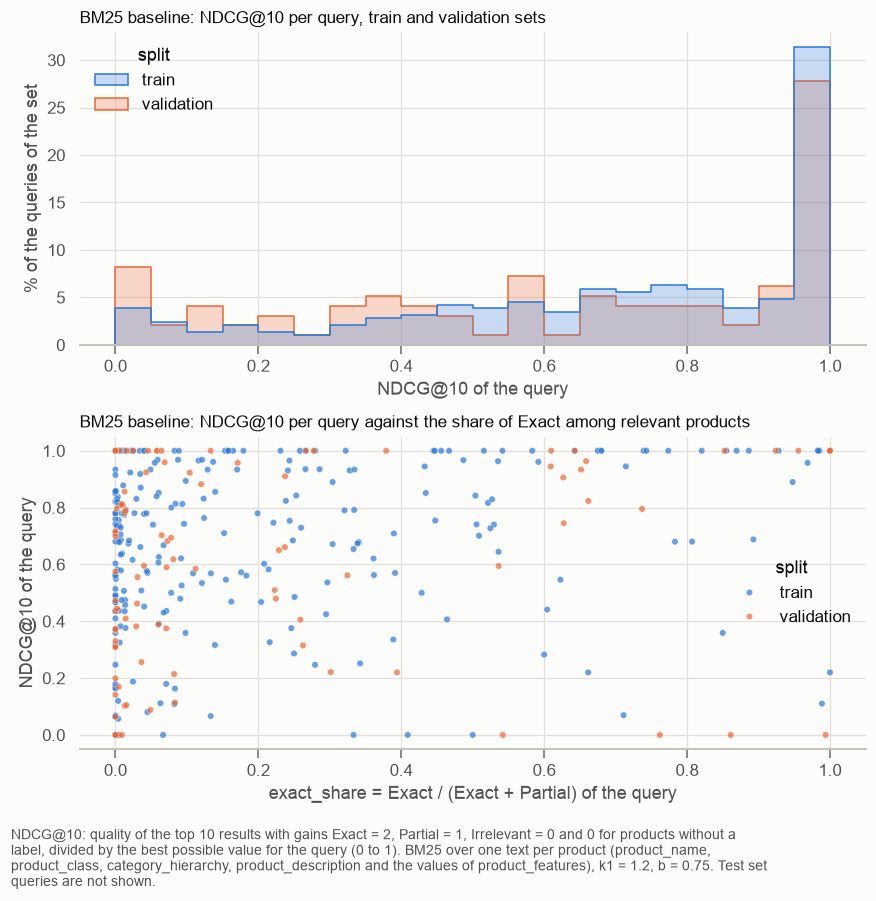

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))

sns.histplot(data=train_validation_per_query, x="ndcg@10", hue="split", bins=20, binrange=(0, 1), stat="percent",
             common_norm=False, element="step", palette=[plots.SERIES_1, plots.SERIES_2], ax=axes[0])
axes[0].set_title("BM25 baseline: NDCG@10 per query, train and validation sets")
axes[0].set_xlabel("NDCG@10 of the query")
axes[0].set_ylabel("% of the queries of the set")

sns.scatterplot(data=train_validation_per_query, x="exact_share", y="ndcg@10", hue="split", palette=[plots.SERIES_1, plots.SERIES_2],
                s=18, alpha=0.7, ax=axes[1])
axes[1].set_title("BM25 baseline: NDCG@10 per query against the share of Exact among relevant products")
axes[1].set_xlabel("exact_share = Exact / (Exact + Partial) of the query")
axes[1].set_ylabel("NDCG@10 of the query")

fig.tight_layout()
plots.add_caption(fig, (
    "NDCG@10: quality of the top 10 results with gains Exact = 2, Partial = 1, Irrelevant = 0 and 0 for "
    "products without a label, divided by the best possible value for the query (0 to 1). "
    "BM25 over one text per product (product_name, product_class, category_hierarchy, product_description "
    "and the values of product_features), k1 = 1.2, b = 0.75. Test set queries are not shown."
))
plt.show()

**Resultados**
- **`exact_share` tem relação fraca e positiva com o NDCG@10:** Spearman correlation de 0,152 no train e no validation set juntos (0,105 no train set, 0,275 no validation set). A suposição 1 aparece, mas fraca. A mediana de `exact_share` é quase igual nos dois sets (0,063 e 0,065), como a stratification buscava.
- **`n_judged` quase não se relaciona com a nota:** 0,085.
- **`irrelevant_share` não se relaciona com a nota:** 0,022. A maior fração de Irrelevant no validation set não explica a nota menor dele.
- **As notas se espalham de 0 a 1 nos dois sets,** com cerca de 30% das queries perto de 1. O validation set tem mais queries perto de 0 (cerca de 8% entre 0 e 0,05, contra 4% no train set), o que puxa a média dele para baixo. Não sabemos qual característica das queries explica isso.

**Limitações**
- A correlação é de um único sistema (o BM25 baseline). Outro sistema pode ter outra relação com a composição dos `label`.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Manter a stratification por `exact_share` e `n_judged`, porque a relação com a nota existe, embora fraca | decidida | revisar a stratification antes de usar o test set; incluir `irrelevant_share` |

### 3.4 · As queries do train set com a menor nota

Para começar a error analysis, as 10 queries do **train set** com o menor NDCG@10, com a composição dos `label` de cada uma.

In [14]:
train_per_query = train_validation_per_query[train_validation_per_query["split"] == "train"].join(queries.set_index("query_id")["query"])
worst_train_queries = train_per_query.nsmallest(10, "ndcg@10")
plots.table(worst_train_queries[["query", "ndcg@10", "judged@10", "condensed_ndcg@10", "Exact", "Partial", "Irrelevant"]],
            "The 10 train queries with the lowest baseline NDCG@10",
            note="Exact, Partial, Irrelevant: judged products of the query with each label.", precision=3)

,query,ndcg@10,judged@10,condensed_ndcg@10,Exact,Partial,Irrelevant
query_id,,,,,,,
142,kitchen wooden stand,0.000,0.100,0.189,5,70,128
179,promo codes or discounts,0.000,0.000,0.000,0,1,0
207,dull bed with shirt head board,0.000,0.000,0.359,0,34,0
345,oriental vanity,0.000,0.900,0.000,0,757,391
370,rug for teen room,0.000,0.000,0.000,1,2,0
448,bed side table,0.000,0.000,0.535,81,117,5
452,day bed indian,0.000,0.000,1.000,0,105,0
462,large bases,0.000,0.000,0.000,0,1,1
465,white abstract,0.000,0.000,0.000,1,1,0


**Resultados**
- **As 10 piores queries do train set têm NDCG@10 = 0, e em 7 delas nenhum dos 10 primeiros tem `label` (judged@10 = 0).** Nesses casos, a nota 0 diz que o BM25 trouxe produtos não julgados, não necessariamente produtos ruins.
- **`bed side table` tem 81 Exact, mas nenhum entre os 10 primeiros;** sem os produtos sem `label`, a nota seria 0,535. `day bed indian` teria condensed NDCG@10 = 1,0. São os casos em que a regra "produto sem `label` = gain 0" mais pesa.
- **Várias têm pouquíssimos `label`:** `promo codes or discounts`, `large bases`, `white abstract` e `rug for teen room` têm de 1 a 3 produtos julgados, então a nota delas é muito instável.
- **`oriental vanity` tem 9 dos 10 primeiros com `label` e nota 0:** todos Irrelevant (a query não tem Exact, só Partial).
- `pedistole sink`, o typo da Etapa 2.2, também está entre as piores.

**Hipóteses para a error analysis (não conferidas)**
- Em `bed side table`, os Exact podem usar outras palavras, como `bedside` ou `nightstand`, e a tokenização não junta `bed side` em `bedside`.
- Em `oriental vanity`, o BM25 pode estar misturando *vanity* de banheiro com penteadeira.

## Etapa 4 · BM25 v2: plurais e `product_features` sem `yes`/`no` e sem números

### 4.0 · A escolha e o motivo

A Etapa 1 mostrou dois problemas do indexed text, e o dataset mostra um terceiro:
- **`yes` e `no`:** cerca de 16% dos tokens do single field (31,4% dos tokens de `product_features`, que é 50,9% do single field) vêm desses values, e nenhuma query do train ou do validation set usa esses tokens (Etapa 1.3).
- **Números de `product_features`:** sem a key, `64.7` ou `500` não dizem a que medida se referem, e podem coincidir por acaso com um número da query (Etapa 1.3).
- **Plurais:** `chairs` não encontra `chair`. O dataset tem as queries `leather chair` e `leather chairs`, e `product_class` usa o plural (`Accent Chairs`, `Benches`, `Mattresses`).

A **BM25 v2** aplica de uma vez as mudanças abaixo, escolhidas antes de ver qualquer número:
1. remoção de plural nos dois lados (queries e produtos), com o *S-stemmer*;
2. em `product_features`, remoção dos values `yes`/`no` e dos values só numéricos (`64.7`, `600 ; 276 ; 456`). Os números dos outros fields ficam, porque em `product_name` costumam ser a medida que a query pede (`36" vanity`).

**Por que sem ablation: restrição de tempo.** As mudanças têm motivo claro nos nossos dados, e a melhoria seguinte, semantic search e hybrid search, deve trazer mais ganho do que ajustes finos do texto. Medir cada mudança separadamente custaria mais trabalho para responder perguntas de pouco impacto.

**Por que só plurais, e não um stemmer completo:** stemmers completos (Porter, Snowball) juntam também `dining` e `dine`, `living` e `live`, o que mistura sentidos num catalog de móveis. O *S-stemmer* só trata plurais.

**Uma regra nossa no S-stemmer:** a versão original transforma `mattresses` em `mattresse` e `benches` em `benche`, que não batem com `mattress` e `bench`. Cerca de 1.000 valores de `product_class` têm plurais desse tipo (`boxes`, `benches`, `mattresses`, `dishes`). Acrescentamos uma regra, aplicada antes das outras: *-es* depois de *ss*, *x*, *z*, *ch* e *sh* é removido. Efeito colateral conhecido: `niches` vira `nich` e não bate com `niche`, que aparece em 2 valores de `product_name`.

**Fontes externas** (separadas do que os nossos dados mostram)
- Harman, *How effective is suffixing?*, JASIS 42(1), 1991 ([DOI](https://doi.org/10.1002/(sici)1097-4571(199101)42:1%3C7::aid-asi2%3E3.0.co;2-p)): define o *S-stemmer* e compara três algoritmos de sufixo em três coleções, sem melhora significativa em nenhum. Não conseguimos abrir o texto completo; as regras seguem a descrição usual do algoritmo.
- Hull, *Stemming algorithms: a case study for detailed evaluation*, JASIS 47(1), 1996 ([RePEc](https://ideas.repec.org/a/bla/jamest/v47y1996i1p70-84.html)): avalia stemmers query a query. Não lemos o texto.
- A literatura não garante ganho com stemming; a nossa justificativa é o problema de plural visível nos nossos dados, e a Etapa 4.3 mede se ajudou.

**Escolhas e alternativas**

| Escolha | Status | Alternativas, se houver tempo |
|---|---|---|
| Aplicar as três mudanças juntas, sem ablation | decidida | ablation de cada mudança |
| S-stemmer com a regra extra de *-es* | decidida | Porter; Snowball; Krovetz, que usa dicionário para não juntar palavras de sentidos diferentes; lemmatization |
| Tirar só os números de `product_features` | decidida | tirar números de todos os fields; tratá-los como medidas |
| Tirar `yes`/`no` de `product_features` | decidida | trocar `key : yes` pela key (testado na Etapa 5) |
| Single field | decidida | um índice por field (BM25F ou soma ponderada) |

### 4.1 · O efeito no indexed text

In [15]:
v2_tokens = retrieval.single_field_tokens(products, **retrieval.V2_TEXT)

indexed_text_change = pd.DataFrame({
    "baseline": [baseline_tokens.map(len).median(), baseline_tokens.map(len).sum(), len({token for tokens in baseline_tokens for token in tokens})],
    "v2": [v2_tokens.map(len).median(), v2_tokens.map(len).sum(), len({token for tokens in v2_tokens for token in tokens})],
}, index=pd.Index(["median tokens per product", "total tokens", "vocabulary"], name="measure"))
indexed_text_change["change_pct"] = (indexed_text_change["v2"] / indexed_text_change["baseline"] - 1) * 100
display(plots.table(indexed_text_change, "Size of the indexed text: baseline vs BM25 v2"))

EXAMPLE_QUERIES = ["leather chairs", "mattresses", "wood benches", "36 inch vanity"]
plots.table(pd.DataFrame({
    "query": EXAMPLE_QUERIES,
    "baseline_tokens": [text.tokenize(query_text) for query_text in EXAMPLE_QUERIES],
    "v2_tokens": [text.tokenize(query_text, stem=True) for query_text in EXAMPLE_QUERIES],
}).set_index("query"), "Tokens of example queries in the baseline and in BM25 v2 (plural removal)")

,baseline,v2,change_pct
measure,,,
median tokens per product,159.0,120.0,-24.5
total tokens,"7,204,605.0","5,523,197.0",-23.3
vocabulary,"54,416.0","48,185.0",-11.5


,baseline_tokens,v2_tokens
query,,
leather chairs,"['leather', 'chairs']","['leather', 'chair']"
mattresses,['mattresses'],['mattress']
wood benches,"['wood', 'benches']","['wood', 'bench']"
36 inch vanity,"['36', 'inch', 'vanity']","['36', 'inch', 'vanity']"


**Resultados**
- **O indexed text encolhe cerca de um quarto:** a mediana passa de 159 para 120 tokens por produto (−24,5%), e o total de tokens cai 23,3%.
- **O vocabulary cai 11,5%** (de 54.416 para 48.185), porque singular e plural viram um só token.
- **Os exemplos se comportam como esperado:** `chairs`, `mattresses` e `benches` viram `chair`, `mattress` e `bench`; `36 inch vanity` não muda, porque números fora de `product_features` são mantidos.

### 4.2 · Tuning de `k1` e `b` no train set

A grade foi fixada antes de rodar (`docs/EVALUATION.md`): `k1` em {0,6; 0,9; 1,2; 1,5; 2,0} e `b` em {0,3; 0,5; 0,75; 0,9}, só com o indexed text da v2, nas 287 queries do train set.

**Regra de escolha:** fica a combinação de maior Capped Recall@100 (só Exact); se a diferença para a melhor for menor que 0,005, desempata o NDCG@10. Usamos Capped Recall@100 porque o BM25 vai gerar os candidatos do reranker: um Exact na posição 80 ainda pode subir, um na posição 150 está perdido.

O resultado da combinação escolhida no train set é otimista (é a melhor entre 20) e não entra na comparação entre sistemas.

In [16]:
def grid_labels(grid: pd.DataFrame) -> pd.DataFrame:
    """Label the rows and columns of a k1 x b grid as 'k1 = ...' and 'b = ...'."""
    return grid.rename(index=lambda k1: f"k1 = {k1}", columns=lambda b: f"b = {b}").rename_axis(index=None, columns=None)


train_queries = evaluate.split_queries(queries, query_split, "train")
validation_queries = evaluate.split_queries(queries, query_split, "validation")

start = time.perf_counter()
v2_tuning, v2_tuning_per_query = evaluate.tune_bm25(v2_tokens, stem=True, queries=train_queries, labels=labels_by_query)
v2_tuning_seconds = time.perf_counter() - start
print(f"grid of {len(v2_tuning)} combinations in {v2_tuning_seconds:.0f} s")

display(plots.table(v2_tuning.pivot(index="k1", columns="b", values="capped_recall@100").pipe(grid_labels),
                    "BM25 v2 tuning: Capped Recall@100 (Exact only) on the train set, by k1 and b", precision=3))
display(plots.table(v2_tuning.pivot(index="k1", columns="b", values="ndcg@10").pipe(grid_labels),
                    "BM25 v2 tuning: NDCG@10 on the train set, by k1 and b", precision=3))
v2_chosen = evaluate.select_tuned(v2_tuning)
v2_chosen_key = (float(v2_chosen["k1"]), float(v2_chosen["b"]))
print(f"chosen: k1 = {v2_chosen_key[0]}, b = {v2_chosen_key[1]} | train capped_recall@100 = {v2_chosen['capped_recall@100']:.3f}, "
      f"ndcg@10 = {v2_chosen['ndcg@10']:.3f}")

grid of 20 combinations in 88 s


,b = 0.3,b = 0.5,b = 0.75,b = 0.9
k1 = 0.6,0.725,0.722,0.723,0.720
k1 = 0.9,0.734,0.729,0.724,0.722
k1 = 1.2,0.736,0.731,0.726,0.720
k1 = 1.5,0.731,0.724,0.722,0.717
k1 = 2.0,0.729,0.725,0.721,0.715


,b = 0.3,b = 0.5,b = 0.75,b = 0.9
k1 = 0.6,0.701,0.705,0.704,0.691
k1 = 0.9,0.712,0.715,0.713,0.700
k1 = 1.2,0.715,0.721,0.719,0.706
k1 = 1.5,0.719,0.724,0.722,0.710
k1 = 2.0,0.723,0.729,0.724,0.708


chosen: k1 = 1.2, b = 0.5 | train capped_recall@100 = 0.731, ndcg@10 = 0.721


As diferenças da grade são maiores que o ruído da amostra de queries? Comparamos cada combinação com a escolhida, query a query, com o paired bootstrap (diferença = combinação − escolhida, intervalo de 95%, train set).

In [17]:
v2_grid_differences = []
for key, per_query in v2_tuning_per_query.items():
    if key == v2_chosen_key:
        continue
    row = {"k1": key[0], "b": key[1]}
    for metric in ["capped_recall@100", "ndcg@10"]:
        difference = evaluate.paired_bootstrap(per_query, v2_tuning_per_query[v2_chosen_key], metric)
        row[f"{metric} difference [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
        row[f"{metric} excludes 0"] = difference["ci_low"] > 0 or difference["ci_high"] < 0
    v2_grid_differences.append(row)
v2_grid_differences = pd.DataFrame(v2_grid_differences).set_index(["k1", "b"])
display(plots.table(v2_grid_differences,
                    f"BM25 v2 tuning: each grid combination minus the chosen one (k1 = {v2_chosen_key[0]}, b = {v2_chosen_key[1]}), train set",
                    note="Mean paired difference with 95% paired bootstrap interval. excludes 0: the interval does not contain 0."))
plots.table(v2_grid_differences[["capped_recall@100 excludes 0", "ndcg@10 excludes 0"]].sum().rename("combinations").to_frame(),
            f"Number of the {len(v2_grid_differences)} other combinations whose difference interval excludes 0")

,combinations
capped_recall@100 excludes 0,12
ndcg@10 excludes 0,11


**Resultados**
- **Combinação escolhida: `k1 = 1.2`, `b = 0.5`.** O maior Capped Recall@100 do train set é 0,736 (`k1 = 1.2`, `b = 0.3`). Quatro combinações, incluindo essa, ficam a menos de 0,005 do máximo, e entre elas `k1 = 1.2`, `b = 0.5` tem o maior NDCG@10 (0,721), então vence pelo desempate.
- **As diferenças entre combinações são pequenas, mas muitas não são ruído.** Contra a escolhida, a diferença de Capped Recall@100 vai de −0,016 a +0,005, e a de NDCG@10 de −0,030 a +0,007. Mesmo assim, 12 das 19 combinações têm Capped Recall@100 menor com intervalo que exclui 0, e 11 têm NDCG@10 diferente com intervalo que exclui 0. O paired bootstrap compara as mesmas queries, então detecta diferenças pequenas.
- **`b` alto (0,9) é pior em quase todas as linhas;** as combinações que não se distinguem da escolhida em Capped Recall@100 são principalmente as de `b = 0.3`.
- **Nenhuma combinação supera a escolhida nas duas métricas com intervalo que exclui 0.** A única com NDCG@10 maior e intervalo acima de 0 (`k1 = 2.0`, `b = 0.5`, +0,007) não se distingue em Capped Recall@100.
- **No train set, a mudança de texto pesa mais que `k1` e `b`:** com os valores padrão (`k1 = 1.2`, `b = 0.75`), a v2 tem Capped Recall@100 de 0,726, contra 0,697 do baseline (Etapa 3.1).
- Na execução salva, o tuning levou 88 s (20 índices, reaproveitando a tokenização).

**Limitações**
- O resultado do train set é otimista para a combinação escolhida (a melhor entre 20) e serve só para escolher.
- Os intervalos não corrigem para 19 comparações; descrevem o tamanho das diferenças, sem testar cada uma.

### 4.3 · A v2 no validation set, contra o baseline

Uma única rodada no validation set, com a combinação escolhida no train set. A comparação usa o paired bootstrap nas 97 queries do validation set (diferença v2 − baseline, intervalo de 95%).

In [18]:
METRICS = ["ndcg@10", "mrr@10", "capped_recall@50", "capped_recall@100", "capped_recall@200", "judged@10", "condensed_ndcg@10"]

v2_index = retrieval.BM25Index(v2_tokens.index.to_list(), v2_tokens.to_list(), k1=v2_chosen_key[0], b=v2_chosen_key[1], stem=True)


def v2_search(query_text: str, k: int) -> list[int]:
    return v2_index.search(query_text, k=k)["product_id"].tolist()


v2_validation_per_query = evaluate.evaluate_system(v2_search, validation_queries, labels_by_query)
baseline_validation_per_query = baseline_per_query["validation"]

v2_vs_baseline = evaluate.compare_systems(v2_validation_per_query, baseline_validation_per_query, METRICS, name_a="v2", name_b="baseline")
display(plots.table(v2_vs_baseline[["baseline_ci", "v2_ci", "difference_ci", "interval_excludes_0", "n_queries",
                                    "share_v2_better", "share_baseline_better"]],
                    "BM25 v2 vs baseline on the validation set",
                    note="*_ci: mean with 95% bootstrap interval. difference_ci: mean paired difference v2 - baseline, with 95% interval. "
                         "share_*_better: share of queries where that system scores higher.", precision=3))
plots.table(pd.DataFrame({
    system: per_query["latency_ms"].quantile([0.5, 0.95]).set_axis(["latency_ms_p50", "latency_ms_p95"])
    for system, per_query in [("baseline", baseline_validation_per_query), ("v2", v2_validation_per_query)]
}), "Latency of one search (k = 200), validation set: baseline vs BM25 v2", precision=2)

,baseline_ci,v2_ci,difference_ci,interval_excludes_0,n_queries,share_v2_better,share_baseline_better
ndcg@10,0.620 [0.555; 0.687],0.653 [0.589; 0.718],0.033 [0.014; 0.056],True,97,0.474,0.175
mrr@10,0.610 [0.516; 0.704],0.661 [0.564; 0.752],0.051 [0.013; 0.093],True,77,0.156,0.091
capped_recall@50,0.611 [0.529; 0.692],0.651 [0.572; 0.730],0.041 [0.018; 0.063],True,77,0.377,0.130
capped_recall@100,0.702 [0.626; 0.778],0.705 [0.628; 0.778],0.003 [-0.047; 0.046],False,77,0.364,0.195
capped_recall@200,0.771 [0.705; 0.833],0.786 [0.715; 0.851],0.015 [-0.025; 0.051],False,77,0.312,0.117
judged@10,0.756 [0.695; 0.811],0.782 [0.719; 0.839],0.026 [0.004; 0.050],True,96,0.240,0.125
condensed_ndcg@10,0.781 [0.730; 0.835],0.799 [0.749; 0.851],0.018 [-0.007; 0.044],False,97,0.330,0.206


,baseline,v2
latency_ms_p50,1.55,0.85
latency_ms_p95,6.72,3.27


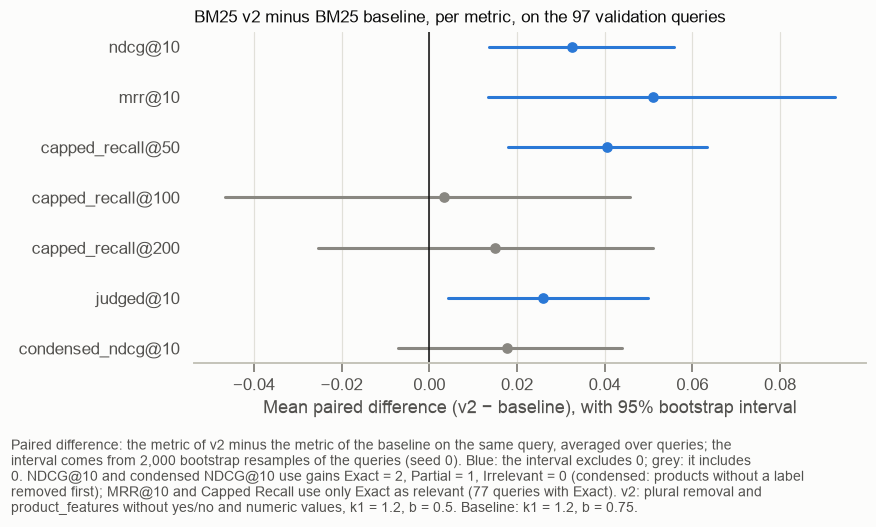

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
plots.difference_plot(ax, list(v2_vs_baseline.index), v2_vs_baseline["difference"],
                      v2_vs_baseline["difference_ci_low"], v2_vs_baseline["difference_ci_high"])
ax.set_title("BM25 v2 minus BM25 baseline, per metric, on the 97 validation queries")
ax.set_xlabel("Mean paired difference (v2 − baseline), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of v2 minus the metric of the baseline on the same query, averaged over "
    "queries; the interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval "
    "excludes 0; grey: it includes 0. NDCG@10 and condensed NDCG@10 use gains Exact = 2, Partial = 1, "
    "Irrelevant = 0 (condensed: products without a label removed first); MRR@10 and Capped Recall use only "
    "Exact as relevant (77 queries with Exact). v2: plural removal and product_features without yes/no and "
    "numeric values, k1 = 1.2, b = 0.5. Baseline: k1 = 1.2, b = 0.75."
))
plt.show()

**Resultados**
- **A v2 melhora a ordem do topo no validation set:** NDCG@10 de 0,620 para 0,653 (+0,033 [0,014; 0,056]), MRR@10 de 0,610 para 0,661 (+0,051 [0,013; 0,093]) e Capped Recall@50 de 0,611 para 0,651 (+0,041 [0,018; 0,063]). Os três intervalos ficam acima de 0. O NDCG@10 melhora em 47% das queries e piora em 18%.
- **Mas não melhora o Capped Recall@100, a métrica do tuning:** 0,702 para 0,705 (+0,003 [−0,047; 0,046]). O Capped Recall@200 também não muda de forma clara (+0,015 [−0,025; 0,051]). Ou seja, a v2 sobe os Exact dentro dos 100 primeiros, mas não traz mais Exact para dentro deles.
- **Primeira checagem da regra "produto sem `label` = gain 0":** no condensed NDCG@10, a diferença cai para +0,018 [−0,007; 0,044], e o intervalo passa a incluir 0. A v2 também tem judged@10 maior (+0,026). Parte do ganho de NDCG@10 vem de trazer mais produtos julgados para o topo, e não sabemos se os produtos sem `label` que saíram eram relevantes. A regra não inverte a comparação (a v2 continua à frente nas duas versões), mas deixa a vantagem menos segura.
- **A latência fica na mesma ordem de grandeza:** na execução salva, p50 de 1,6 ms (baseline) e 0,8 ms (v2), e p95 de 6,7 ms e 3,3 ms. Esses tempos variam entre execuções (Etapa 2.4), então uma única execução não mostra se uma versão é mais rápida que a outra.

**Limitações**
- Só 77 queries do validation set têm Exact, então os intervalos do Capped Recall são largos: uma diferença de 0,03 não seria detectada.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| A v2 passa a ser o BM25 de referência | decidida | manter o baseline, por ser mais simples (descartado: a diferença de NDCG@10 tem intervalo acima de 0) |

## Resumo da Etapa 4

- **A BM25 v2 (sem plurais, `product_features` sem `yes`/`no` e sem números; `k1 = 1.2`, `b = 0.5`) passa a ser o BM25 de referência:** NDCG@10 de 0,653 no validation set [0,589; 0,718], contra 0,620 do baseline, um ganho de +0,033 [0,014; 0,056].
- **O ganho está na ordem do topo, não na cobertura dos 100 candidatos:** o Capped Recall@100 fica em 0,705, praticamente igual ao do baseline.
- **O que isso implica:** com BM25 sozinho, o ranking recebe perto de 70% dos Exact nos 100 candidatos. Aumentar essa cobertura é o papel da semantic search e da hybrid search, que vêm a seguir.
- As três mudanças foram aplicadas juntas, sem ablation, então não sabemos qual delas responde pelo ganho.

## Etapa 5 · BM25 v3: a key dos values `yes`

A v2 tira `yes` e `no` de `product_features` e, com isso, perde a informação de que o produto **tem** a característica: `upholstered : yes` some do texto. A v3 é igual à v2, mas um key:value pair com value `yes` entra pelo texto da key (`upholstered : yes` vira `upholstered`). `no` e números continuam removidos.

A regra foi registrada no `docs/EVALUATION.md` antes de rodar: mesma grade de `k1` e `b` e mesma regra de escolha da v2, no train set; uma rodada no validation set, comparada com a v2 pelo paired bootstrap.

### 5.1 · As keys com value `yes`

Antes de rodar, olhamos quais keys entram no texto e quantos tokens delas coincidem com tokens das queries do train e do validation set.

In [20]:
key_value_pairs = products["product_features"].map(data.parse_product_features)
yes_keys = pd.Series([key for pairs in key_value_pairs for key, value in pairs if value.strip().lower() == "yes"])
train_validation_query_tokens = {token for tokens in train_validation_queries["query"].map(lambda query_text: text.tokenize(query_text, stem=True))
                                 for token in tokens}
yes_key_tokens = pd.Series([token for key in yes_keys for token in text.tokenize(key, stem=True)])

display(plots.table(pd.Series({
    "key:value pairs with value yes": len(yes_keys),
    "distinct keys": yes_keys.nunique(),
    "products with at least one": int(key_value_pairs.map(lambda pairs: any(value.strip().lower() == "yes" for _, value in pairs)).sum()),
    "token occurrences in these keys": len(yes_key_tokens),
}, name="count"), "key:value pairs of product_features whose value is yes"))
print(f"% of those token occurrences that also appear in a train or validation query: "
      f"{yes_key_tokens.isin(train_validation_query_tokens).mean() * 100:.1f}%")
display(plots.table(yes_keys.value_counts().head(15).rename_axis("key").rename("pairs").to_frame(),
                    "The 15 most common keys with value yes"))
plots.table(yes_key_tokens[yes_key_tokens.isin(train_validation_query_tokens)].value_counts().head(15)
            .rename_axis("token").rename("occurrences").to_frame(),
            "The 15 most common tokens of yes keys that also appear in a train or validation query",
            note="Tokens after plural removal, as in BM25 v2 and v3.")

,count
key:value pairs with value yes,"363,512"
distinct keys,"2,887"
products with at least one,"41,594"
token occurrences in these keys,"408,616"


% of those token occurrences that also appear in a train or validation query: 9.2%


,pairs
key,
productwarranty,"22,209"
adultassemblyrequired,"19,212"
uniformpackagingandlabelingregulationsuplrcompliant,"13,416"
compositewoodproductcwp,"9,439"
carbphaseiicompliantformaldehydeemissions,"8,150"
tscatitlevicompliantformaldehydeemissions,"7,886"
commercialwarranty,"7,542"
installationrequired,"7,484"
upholstered,"5,468"


,occurrences
token,
upholstered,"5,468"
non,"3,718"
drawer,"2,750"
wood,"2,067"
leg,"1,982"
headboard,"1,579"
cabinet,"1,559"
shelve,"1,508"
code,"1,122"


**Resultados**
- **Os values `yes` são muitos e estão em quase todos os produtos:** 363.512 key:value pairs em 41.594 produtos, com 2.887 keys diferentes.
- **As keys mais comuns são de garantia e de conformidade, escritas como palavras emendadas:** `productwarranty`, `adultassemblyrequired`, `uniformpackagingandlabelingregulationsuplrcompliant`. A tokenização não separa essas palavras, então elas não coincidem com nenhuma query.
- **Só 9,2% das ocorrências de tokens dessas keys coincidem com algum token de query do train ou do validation set.** As que coincidem são keys de uma palavra só: `upholstered`, `drawer`, `wood`, `headboard`, `swivel`, `tufted`.

**O que isso implica**
- Um token de key que não aparece em nenhuma query não muda o score dela, só o tamanho do texto. Por isso, esperamos pouco efeito da v3. A Etapa 5.2 mede.

### 5.2 · Tuning no train set e a v3 no validation set, contra a v2

In [21]:
v3_tokens = retrieval.single_field_tokens(products, **retrieval.V3_TEXT)
print("median tokens per product: v2", v2_tokens.map(len).median(), "| v3", v3_tokens.map(len).median())

v3_tuning, v3_tuning_per_query = evaluate.tune_bm25(v3_tokens, stem=True, queries=train_queries, labels=labels_by_query)
v3_chosen = evaluate.select_tuned(v3_tuning)
v3_chosen_key = (float(v3_chosen["k1"]), float(v3_chosen["b"]))
print(f"chosen for v3: k1 = {v3_chosen_key[0]}, b = {v3_chosen_key[1]} | train capped_recall@100 = {v3_chosen['capped_recall@100']:.3f}, "
      f"ndcg@10 = {v3_chosen['ndcg@10']:.3f}")
display(plots.table(v3_tuning.pivot(index="k1", columns="b", values="capped_recall@100").pipe(grid_labels),
                    "BM25 v3 tuning: Capped Recall@100 (Exact only) on the train set, by k1 and b", precision=3))

v3_vs_v2_train = evaluate.compare_systems(v3_tuning_per_query[v3_chosen_key], v2_tuning_per_query[v2_chosen_key],
                                          ["capped_recall@100", "ndcg@10"], name_a="v3", name_b="v2")
display(plots.table(v3_vs_v2_train[["v2_ci", "v3_ci", "difference_ci", "interval_excludes_0"]],
                    "BM25 v3 vs v2 on the train set, each with its chosen k1 and b",
                    note="Reference only: both are the best of their own grid on these queries, so the values are optimistic."))

v3_index = retrieval.BM25Index(v3_tokens.index.to_list(), v3_tokens.to_list(), k1=v3_chosen_key[0], b=v3_chosen_key[1], stem=True)


def v3_search(query_text: str, k: int) -> list[int]:
    return v3_index.search(query_text, k=k)["product_id"].tolist()


v3_validation_per_query = evaluate.evaluate_system(v3_search, validation_queries, labels_by_query)
v3_vs_v2 = evaluate.compare_systems(v3_validation_per_query, v2_validation_per_query, METRICS, name_a="v3", name_b="v2")
plots.table(v3_vs_v2[["v2_ci", "v3_ci", "difference_ci", "interval_excludes_0", "n_queries", "share_v3_better", "share_v2_better"]],
            "BM25 v3 vs v2 on the validation set",
            note="*_ci: mean with 95% bootstrap interval. difference_ci: mean paired difference v3 - v2, with 95% interval. "
                 "share_*_better: share of queries where that system scores higher.", precision=3)

median tokens per product: v2 120.0 | v3 129.0


chosen for v3: k1 = 1.2, b = 0.5 | train capped_recall@100 = 0.736, ndcg@10 = 0.721


,b = 0.3,b = 0.5,b = 0.75,b = 0.9
k1 = 0.6,0.722,0.722,0.723,0.721
k1 = 0.9,0.731,0.729,0.726,0.723
k1 = 1.2,0.734,0.736,0.726,0.721
k1 = 1.5,0.729,0.729,0.719,0.718
k1 = 2.0,0.729,0.730,0.721,0.717


,v2_ci,v3_ci,difference_ci,interval_excludes_0
capped_recall@100,0.731 [0.691; 0.770],0.736 [0.696; 0.775],0.005 [-0.003; 0.016],False
ndcg@10,0.721 [0.688; 0.755],0.721 [0.688; 0.755],-0.000 [-0.004; 0.003],False


,v2_ci,v3_ci,difference_ci,interval_excludes_0,n_queries,share_v3_better,share_v2_better
ndcg@10,0.653 [0.589; 0.718],0.655 [0.591; 0.720],0.002 [-0.004; 0.009],False,97,0.247,0.216
mrr@10,0.661 [0.564; 0.752],0.660 [0.562; 0.749],-0.001 [-0.018; 0.013],False,77,0.052,0.026
capped_recall@50,0.651 [0.572; 0.730],0.659 [0.579; 0.735],0.007 [-0.006; 0.029],False,77,0.130,0.078
capped_recall@100,0.705 [0.628; 0.778],0.710 [0.637; 0.780],0.005 [-0.009; 0.025],False,77,0.078,0.104
capped_recall@200,0.786 [0.715; 0.851],0.775 [0.705; 0.842],-0.011 [-0.038; 0.005],False,77,0.130,0.052
judged@10,0.782 [0.719; 0.839],0.782 [0.719; 0.840],-0.000 [-0.010; 0.008],False,96,0.073,0.052
condensed_ndcg@10,0.799 [0.749; 0.851],0.798 [0.746; 0.851],-0.001 [-0.005; 0.003],False,97,0.155,0.186


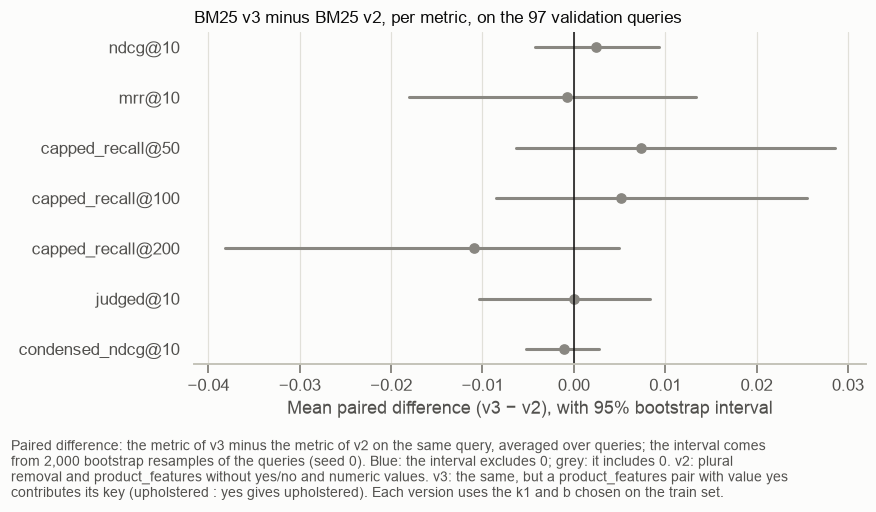

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
plots.difference_plot(ax, list(v3_vs_v2.index), v3_vs_v2["difference"],
                      v3_vs_v2["difference_ci_low"], v3_vs_v2["difference_ci_high"])
ax.set_title("BM25 v3 minus BM25 v2, per metric, on the 97 validation queries")
ax.set_xlabel("Mean paired difference (v3 − v2), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of v3 minus the metric of v2 on the same query, averaged over queries; the "
    "interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval excludes 0; "
    "grey: it includes 0. v2: plural removal and product_features without yes/no and numeric values. v3: the "
    "same, but a product_features pair with value yes contributes its key (upholstered : yes gives "
    "upholstered). Each version uses the k1 and b chosen on the train set."
))
plt.show()

**Resultados**
- **A v3 não se distingue da v2 em nenhuma métrica do validation set:** NDCG@10 de 0,655 contra 0,653 (+0,002 [−0,004; 0,009]); Capped Recall@100 de 0,710 contra 0,705 (+0,005 [−0,009; 0,025]). Todos os intervalos incluem 0; o NDCG@10 melhora em 25% das queries e piora em 22%.
- **No train set também não:** com a mesma combinação escolhida (`k1 = 1.2`, `b = 0.5`), Capped Recall@100 +0,005 [−0,003; 0,016] e NDCG@10 sem diferença.
- **O texto fica 7,5% maior** (mediana de 120 para 129 tokens por produto), sem ganho medido.

**Limitações**
- Com 97 queries no validation set, diferenças de NDCG@10 menores que cerca de 0,01 não seriam detectadas. "Sem efeito mensurável" quer dizer isso, e não que o efeito seja zero.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Manter a v2 como BM25 de referência: pela regra de seleção do protocolo, quando o intervalo da diferença inclui 0, fica o sistema mais simples | decidida | adotar a v3; separar as keys emendadas em palavras (`drawersincluded` → `drawers included`), o que exigiria segmentação de palavras; manter só as keys de uma palavra |